# Chapitre 10 - Cours 2 : stockage distribué, workflows et pannes

Les outils Unix s'arrêtent aux limites d'une machine. Pour traiter des téraoctets, il
faut répartir les données **et** le calcul sur un cluster. Ce cours présente les briques
d'un tel « système d'exploitation distribué » : un système de fichiers distribué qui
découpe et réplique les fichiers, un ordonnanceur qui enchaîne les jobs d'un workflow,
et une stratégie de tolérance aux pannes adaptée à des jobs qui durent des heures. Il
couvre la section *MapReduce and Distributed Filesystems*, ainsi que *MapReduce workflows* et *Designing for frequent faults*.

**Plan.**

1. L'analogie du système d'exploitation distribué.
2. Le système de fichiers distribué : blocs, métadonnées, placement et localité.
3. Survivre aux pannes de disques : réplication ou codes d'effacement.
4. Les workflows : des graphes acycliques de jobs.
5. Pannes et préemption : relancer une tâche, pas tout le job.



In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import batch as B
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Un système d'exploitation distribué (section *MapReduce and Distributed Filesystems*)

Sur la machine du cours 1, trois composants coopéraient : des **périphériques de
stockage** derrière l'interface du système de fichiers, un **ordonnanceur** du noyau qui
décide quel processus tourne sur quel cœur, et des **programmes** reliés par des
tuyaux. Un framework de traitement par lots distribué a exactement les mêmes
composants, à l'échelle d'un cluster. Le livre présente MapReduce comme un cousin des outils Unix, mais réparti sur des milliers de machines : à la place des fichiers locaux, un système de fichiers distribué (HDFS dans Hadoop) ; à la place de l'ordonnanceur du noyau, un gestionnaire de ressources du cluster (YARN pour Hadoop).

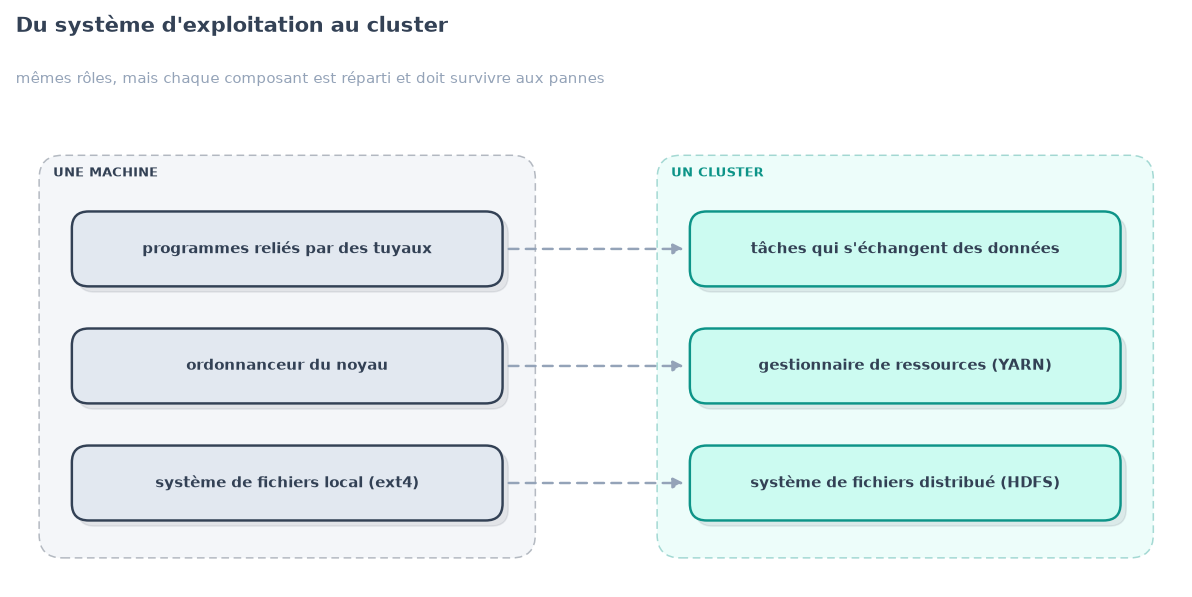

In [2]:
d = Diagram(12.5, 5.2, title="Du système d'exploitation au cluster",
            subtitle="mêmes rôles, mais chaque composant est réparti et doit survivre aux pannes")
d.group(0.3, 0.3, 5.6, 4.6, "une machine", color=SLATE)
d.group(6.9, 0.3, 12.2, 4.6, "un cluster", color=TEAL)
rows = [("programmes reliés par des tuyaux", "tâches qui s'échangent des données", 3.6),
        ("ordonnanceur du noyau", "gestionnaire de ressources (YARN)", 2.35),
        ("système de fichiers local (ext4)", "système de fichiers distribué (HDFS)", 1.1)]
for i, (a, b, y) in enumerate(rows):
    d.box(f"a{i}", 2.95, y, a, color=SLATE, w=4.6, h=0.8, fontsize=9.5)
    d.box(f"b{i}", 9.55, y, b, color=TEAL, w=4.6, h=0.8, fontsize=9.5)
    d.arrow(f"a{i}", f"b{i}", "", color=GRAY, style="dashed")
d.show()

> **À retenir.** Un framework de lots distribué est un « système d'exploitation » de
> cluster : un stockage partagé, un ordonnanceur, et des programmes qui se passent des
> données. Chaque brique doit en plus tolérer la panne d'une machine.

## 2. Le système de fichiers distribué (section *MapReduce and Distributed Filesystems*)

**Le principe.** Un système de fichiers distribué (DFS) comme HDFS découpe chaque
fichier en **blocs** et répartit ces blocs sur les disques des machines du cluster. Sur
chaque machine tourne un démon (*DataNode* dans HDFS) qui sert les blocs stockés
localement, comme des fichiers ordinaires de son système de fichiers. Un service
central, le **NameNode**, tient les **métadonnées** : quels blocs composent quel fichier,
et sur quelles machines se trouve chaque bloc. Un client demande au NameNode où lire, puis
lit directement les blocs auprès des DataNodes.

**Des blocs énormes.** Là où ext4 utilise des blocs de 4 Kio, HDFS utilise par défaut
**128 Mio**. Deux raisons : moins de blocs, donc moins de métadonnées (crucial à
l'échelle du pétaoctet, car le NameNode les garde en mémoire) ; et une lecture longue et
séquentielle par bloc, si bien que le temps d'accès devient négligeable devant le temps
de transfert. Le dernier bloc d'un fichier n'occupe que la place nécessaire.

fichier de 1 000 Mio en blocs de 128 Mio : [128, 128, 128, 128, 128, 128, 128, 104]


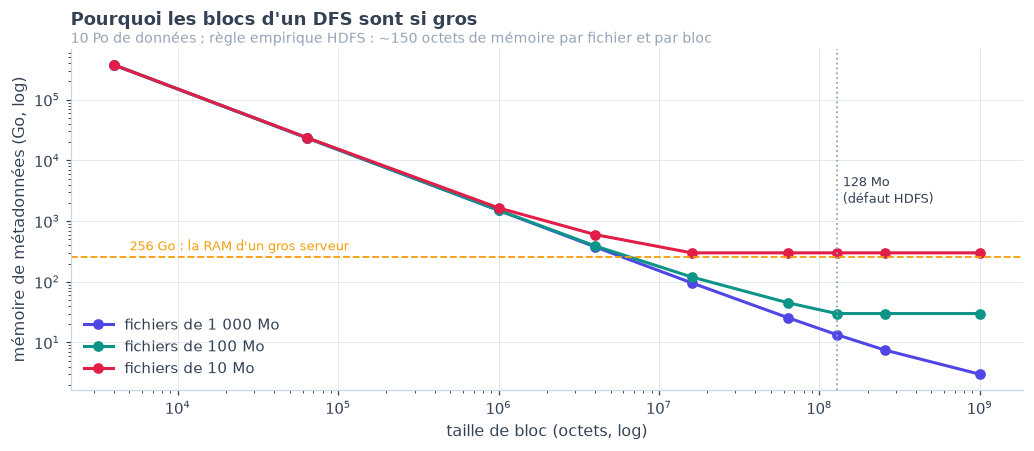

In [3]:
def blocs(taille_mio, bloc_mio=128):
    n_pleins, reste = divmod(taille_mio, bloc_mio)
    return [bloc_mio] * int(n_pleins) + ([reste] if reste else [])

print("fichier de 1 000 Mio en blocs de 128 Mio :", blocs(1000))

total = 10e15                      # 10 Po de données
taille_bloc = np.array([4e3, 64e3, 1e6, 4e6, 16e6, 64e6, 128e6, 256e6, 1e9])
fig, ax = plt.subplots(figsize=(9.5, 4.2))
for fs, c in [(1e9, INDIGO), (100e6, TEAL), (10e6, ROSE)]:
    mem = [B.namenode_memory(total, b, fs) for b in taille_bloc]
    ax.loglog(taille_bloc, np.array(mem) / 1e9, "o-", color=c, label=f"fichiers de {fs / 1e6:,.0f} Mo".replace(",", " "))
ax.axvline(128e6, color=GRAY, ls=":", lw=1.2)
ax.text(140e6, 2e3, "128 Mo\n(défaut HDFS)", fontsize=8.5, color=SLATE)
ax.axhline(256, color=AMBER, ls="--", lw=1.2)
ax.text(5e3, 330, "256 Go : la RAM d'un gros serveur", fontsize=8.5, color=AMBER)
ax.set_xlabel("taille de bloc (octets, log)"); ax.set_ylabel("mémoire de métadonnées (Go, log)")
ax.set_title("Pourquoi les blocs d'un DFS sont si gros")
subtitle(ax, "10 Po de données ; règle empirique HDFS : ~150 octets de mémoire par fichier et par bloc")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

Avec des blocs de 4 Kio, les métadonnées de 10 Po demanderaient des centaines de
téraoctets de RAM ; avec 128 Mo, il en faut de 13 à 300 Go selon la taille des fichiers. La figure
montre aussi le talon d'Achille du NameNode : au-delà d'une certaine taille de bloc, ce
sont les **petits fichiers** qui dominent (un fichier coûte au moins une entrée, quelle
que soit sa taille). D'où la consigne classique : produire peu de gros fichiers.

**Placement des répliques.** Pour survivre à la panne d'une machine, chaque bloc est
copié sur plusieurs DataNodes (3 par défaut). La politique de HDFS tient compte des
**racks** (armoires partageant un commutateur et une alimentation) : la première copie
sur un nœud, la deuxième sur un **autre rack**, la troisième sur le même rack que la
deuxième. Une panne de rack entier ne détruit donc jamais toutes les copies, tout en
limitant le trafic entre racks à l'écriture. Simulons ce placement sur 4 racks de 10
machines.

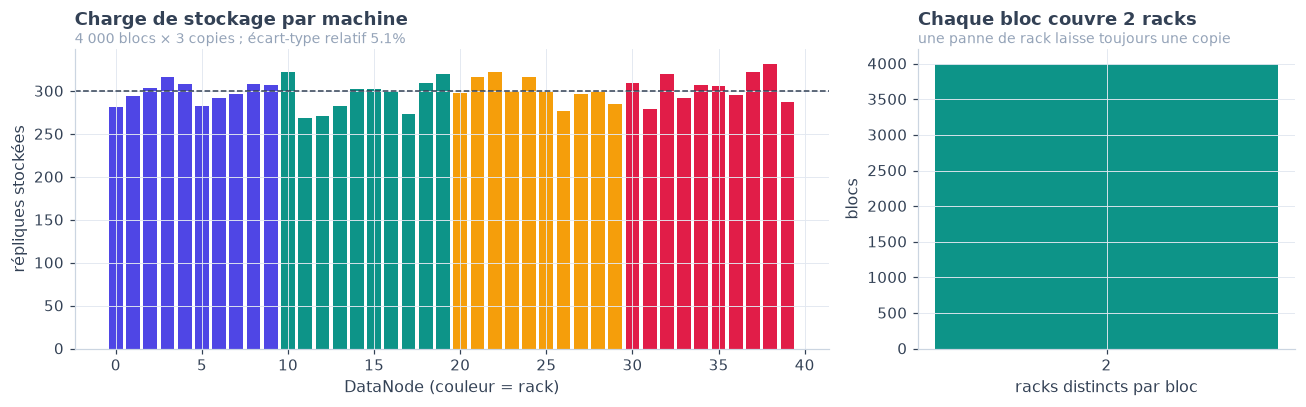

In [4]:
n_nodes, par_rack = 40, 10
pl = B.place_blocks(4000, n_nodes, 3, nodes_per_rack=par_rack, seed=1)
par_noeud = np.bincount(pl.ravel(), minlength=n_nodes)
racks_par_bloc = np.array([len({B.rack_of(int(x), par_rack) for x in b}) for b in pl])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 1]})
axes[0].bar(range(n_nodes), par_noeud, color=[COLORS[B.rack_of(i, par_rack)] for i in range(n_nodes)])
axes[0].axhline(par_noeud.mean(), color=SLATE, ls="--", lw=1)
axes[0].set_xlabel("DataNode (couleur = rack)"); axes[0].set_ylabel("répliques stockées")
axes[0].set_title("Charge de stockage par machine")
subtitle(axes[0], f"4 000 blocs × 3 copies ; écart-type relatif {par_noeud.std() / par_noeud.mean():.1%}")
vals, cnt = np.unique(racks_par_bloc, return_counts=True)
axes[1].bar([str(v) for v in vals], cnt, color=TEAL)
axes[1].set_xlabel("racks distincts par bloc"); axes[1].set_ylabel("blocs")
axes[1].set_title("Chaque bloc couvre 2 racks")
subtitle(axes[1], "une panne de rack laisse toujours une copie")
plt.tight_layout(); plt.show()

**Localité des données.** Puisque chaque bloc existe en plusieurs exemplaires,
l'ordonnanceur peut lancer la tâche qui lit un bloc **sur une des machines qui le
détiennent** : la lecture se fait alors sur le disque local, sans traverser le réseau.
C'est le principe « déplacer le calcul vers les données » : le code d'une tâche pèse
quelques mégaoctets, son entrée 128 Mo. Mais si ces machines sont déjà occupées par
d'autres jobs, la tâche part ailleurs, de préférence sur le même rack. La simulation
mesure la part de tâches locales selon l'occupation du cluster et le nombre de copies.

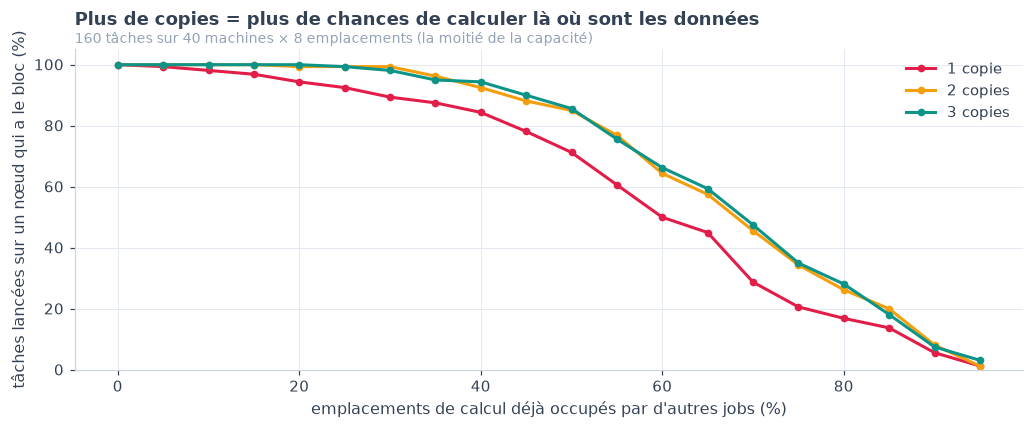

In [5]:
busy = np.linspace(0, 0.95, 20)
fig, ax = plt.subplots(figsize=(9.5, 4))
for r, c in [(1, ROSE), (2, AMBER), (3, TEAL)]:
    plr = B.place_blocks(160, n_nodes, r, nodes_per_rack=par_rack, seed=2)
    loc = [B.schedule_locality(plr, n_nodes, slots_per_node=8, busy_fraction=b, nodes_per_rack=par_rack, seed=3)["nœud"]
           for b in busy]
    ax.plot(busy * 100, np.array(loc) * 100, "o-", ms=4, color=c, label=f"{r} copie{'s' if r > 1 else ''}")
ax.set_xlabel("emplacements de calcul déjà occupés par d'autres jobs (%)")
ax.set_ylabel("tâches lancées sur un nœud qui a le bloc (%)")
ax.set_ylim(0, 105)
ax.set_title("Plus de copies = plus de chances de calculer là où sont les données")
subtitle(ax, "160 tâches sur 40 machines × 8 emplacements (la moitié de la capacité)")
ax.legend()
plt.tight_layout(); plt.show()

Avec une seule copie, la localité baisse dès que le cluster est un peu chargé : il suffit
que l'unique machine qui détient le bloc soit pleine. Avec deux ou trois copies,
l'ordonnanceur a le choix et la chute est retardée (85 % de tâches locales à 50 %
d'occupation, contre 70 % avec une copie) ; quand le cluster est presque plein, plus
personne n'est local et les lectures passent par le réseau, de préférence à l'intérieur
du rack. La réplication sert donc deux fois : à la
durabilité et à la souplesse de l'ordonnancement.

> **À retenir.** Un DFS découpe les fichiers en gros blocs (128 Mo), répliqués sur
> plusieurs machines et plusieurs racks ; un service de métadonnées (le NameNode) sait où
> est chaque bloc. Les gros blocs limitent les métadonnées, les copies permettent de
> lancer les tâches là où sont les données.

## 3. Survivre aux pannes de disques : réplication ou codes d'effacement

Les DFS tournent sur du matériel ordinaire, moins cher mais moins fiable que du matériel
haut de gamme : des disques et des machines tombent en panne en permanence. Deux façons
de ne rien perdre :

- la **réplication** : $r$ copies complètes de chaque bloc (chapitre 5) ;
  on perd un bloc si les $r$ copies disparaissent avant d'avoir été refaites ; coût de
  stockage : $r$ ;
- les **codes d'effacement** (*erasure coding*, par exemple Reed-Solomon) : on découpe
  un bloc en $k$ fragments et on calcule $m$ fragments de **parité** ; n'importe quels
  $k$ fragments parmi les $k+m$ suffisent à tout reconstruire. Coût : $(k+m)/k$. C'est
  le principe des grappes RAID, mais à travers le réseau du centre de données, sans
  matériel spécial.

Le cas le plus simple est $m = 1$ : la parité est le **XOR** des $k$ fragments. Si un
fragment disparaît, le XOR des survivants et de la parité le redonne, car
$a \oplus a = 0$.

In [6]:
rng = np.random.default_rng(7)
fragments = [rng.integers(0, 256, 16, dtype=np.uint8).tobytes() for _ in range(4)]
parite = B.xor_parity(fragments)
perdu = 2
reconstruit = B.xor_recover([f for i, f in enumerate(fragments) if i != perdu], parite)
pd.DataFrame({"fragment": [f"d{i}" for i in range(4)] + ["parité"],
              "octets (hex)": [f.hex(" ") for f in fragments + [parite]]}).assign(
    statut=["", "", "PERDU, reconstruit" if reconstruit == fragments[perdu] else "erreur", "", ""])

,fragment,octets (hex),statut
0,d0,8b 4a e5 f1 a9 41 06 a0 95 6a 26 af bc cd af e5,
1,d1,62 f9 0a 94 5f 56 93 c6 42 27 6a d5 ab 2d a7 39,
2,d2,45 51 37 0e 99 b2 d7 4c 34 27 fa 48 d7 32 a1 df,"PERDU, reconstruit"
3,d3,70 ac a1 e9 26 11 59 01 dd 06 f2 7f 8f 06 3c d2,
4,parité,dc 4e 79 82 49 b4 1b 2b 3e 6c 44 4d 4f d4 95 d1,


Reed-Solomon généralise ce calcul (arithmétique dans un corps fini) pour tolérer $m$
pertes quelconques. Comparons la probabilité de perdre un bloc en supposant que chaque
fragment est perdu, indépendamment, avec une probabilité $p$ avant d'être réparé :
réplication $p^r$, code $(k, m)$ : probabilité que plus de $m$ des $k+m$ fragments
soient perdus (loi binomiale).

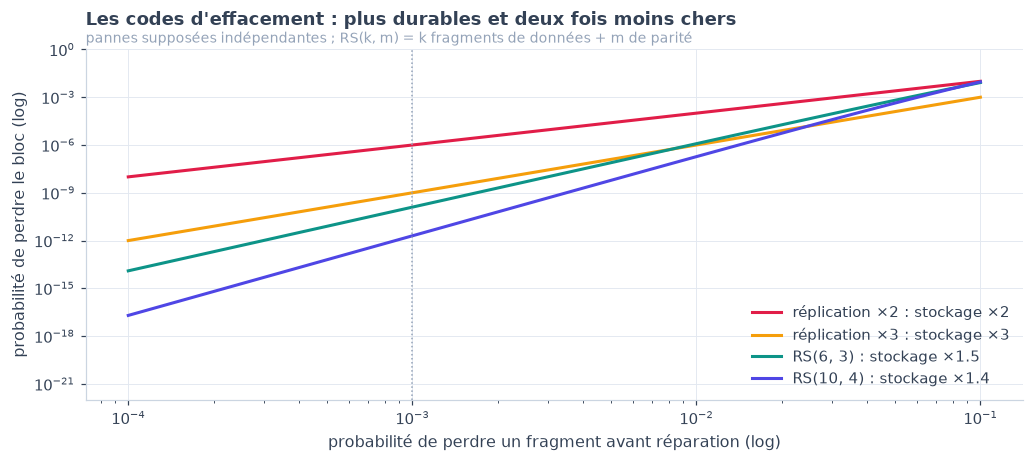

,coût de stockage,"P(perte) si p = 0,001"
schéma,,
réplication ×2,2.0,1.000e-06
réplication ×3,3.0,1.000e-09
"RS(6, 3)",1.5,1.255e-10
"RS(10, 4)",1.4,1.987e-12


In [7]:
p = np.logspace(-4, -1, 50)
schemas = [("réplication ×2", lambda p: B.p_loss_replication(p, 2), 2.0, ROSE),
           ("réplication ×3", lambda p: B.p_loss_replication(p, 3), 3.0, AMBER),
           ("RS(6, 3)", lambda p: B.p_loss_erasure(p, 6, 3), 1.5, TEAL),
           ("RS(10, 4)", lambda p: B.p_loss_erasure(p, 10, 4), 1.4, INDIGO)]
fig, ax = plt.subplots(figsize=(9.5, 4.3))
for nom, f, cout, c in schemas:
    ax.loglog(p, [f(x) for x in p], color=c, label=f"{nom} : stockage ×{cout:g}")
ax.axvline(1e-3, color=GRAY, ls=":", lw=1)
ax.set_xlabel("probabilité de perdre un fragment avant réparation (log)")
ax.set_ylabel("probabilité de perdre le bloc (log)")
ax.set_ylim(1e-22, 1)
ax.set_title("Les codes d'effacement : plus durables et deux fois moins chers")
subtitle(ax, "pannes supposées indépendantes ; RS(k, m) = k fragments de données + m de parité")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
pd.DataFrame([(nom, cout, f(1e-3)) for nom, f, cout, _ in schemas],
             columns=["schéma", "coût de stockage", "P(perte) si p = 0,001"]).set_index("schéma")

Pour $p = 10^{-3}$, RS(6, 3) perd un bloc avec une probabilité de l'ordre de $10^{-10}$,
bien moins que la triple réplication ($10^{-9}$), pour moitié moins de disque. Le prix est
ailleurs : reconstruire un fragment demande de lire $k$ autres fragments sur $k$
machines (trafic réseau et calcul), et une lecture normale doit assembler plusieurs
fragments au lieu de lire une copie locale. On réserve donc souvent les codes
d'effacement aux données froides, et la réplication aux données chaudes. Rappelons aussi
que l'hypothèse d'indépendance est optimiste (chapitre 1 : les pannes
corrélées dominent en pratique).

**Rien de partagé.** Un DFS suit l'architecture **shared-nothing** (aucune ressource
partagée entre les machines, seulement un réseau ordinaire), à l'opposé des baies de
stockage NAS ou SAN, qui centralisent les disques dans un équipement spécialisé relié par
un réseau dédié (Fibre Channel) : c'est une architecture à disques partagés.

> **À retenir.** Réplication ($r$ copies, coût $r$) ou codes d'effacement ($k+m$
> fragments, coût $(k+m)/k$) : les seconds offrent une durabilité comparable ou
> meilleure pour bien moins de stockage, au prix de reconstructions plus coûteuses en
> réseau.